### Build the Basic ChatBot with Langgraph(Graph API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

#add_messages are known as reducers which are used to append the messages to maintain the data history


In [2]:
class State(TypedDict):
    #Messsages have the type "list". The `add_messages` function
    #in the annotation defines how this state key should be updted
    # (in this case it appends the messages rather than overwriting them)
    messages: Annotated[list, add_messages]



In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-120b")


In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000011C127F34D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000011C129942F0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
type(init_chat_model)

function

In [7]:
llm=init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000011C12986350>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000011C12986D50>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [9]:
graph_builder=StateGraph(State)

##Add the nodes
graph_builder.add_node("llmchatbot", chatbot)

#Adding Edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

#complie the graph
graph=graph_builder.compile()

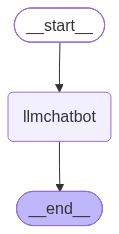

In [10]:
## Visualize the graph

from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    pass





In [11]:
response=graph.invoke({"messages":"Hi"})

In [12]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [29]:
for event in graph.stream({"messages":"Hi, how are you?"}):
    
    for value in event.values():
        print(value['messages'][-1].content)

Hello! I'm doing great, thank you for asking. How can I help you today?


### ChatBot with Tool

In [46]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_length=2)
tool.invoke("What is langchain?")



{'query': 'What is langchain?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://cloud.google.com/use-cases/langchain',
   'title': 'What Is LangChain? Examples and definition | Google Cloud',
   'content': 'Page Contents\n\n   Topics\n\n   LangChain\n\n# What is LangChain?\n\nLangChain is an open-source orchestration framework that simplifies building applications with large language models (LLMs). It provides tools and components to connect LLMs with various data sources, enabling the creation of complex, multi-step workflows. [...] LangChain works by "chaining" together different components to create a cohesive workflow for LLM-powered applications. This modular approach breaks down complex language-based AI systems into reusable parts. When a user submits a query, LangChain can process this input through a series of steps.\n\nFor example, a typical workflow might involve: [...] Available as libraries in Python and JavaScript, LangChain hel

In [41]:
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a: first int
        b: second int
    """
    return a*b

In [47]:
tools=[tool,multiply]
llm_with_tools=llm.bind_tools(tools)

In [48]:

llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000011C12986350>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000011C12986D50>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

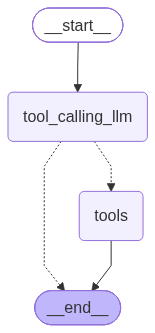

In [50]:
# StateGraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def tool_calling_llm(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message(result) from assisstant is a tool call -> tool condition routes to tools
    #If latest message(result) from assisstant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [53]:
response=graph.invoke({"messages": "What is the recent ai news?"})

In [54]:
response["messages"][-1].content

'{"query": "AI news October 2026 latest AI developments", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://digitnewz.in/ai-news-october-2026", "title": "Top AI News October 2026: Latest AI Trends and Updates", "content": "## Conclusion\\n\\nThe AI news of October 2026 is likely to focus on more than individual chatbot updates. AI agents, specialized professional systems, generative media, developer tools, infrastructure and safety are all becoming important parts of the industry.\\n\\nAs companies continue competing to develop and deploy increasingly capable AI, users can expect artificial intelligence to become more integrated into the digital tools they already use. [...] One of the biggest developments heading into October is the growing importance of AI agents. OpenAI recently introduced its Agents API, designed to help developers build applications capable of performing multi-step tasks. OpenAI’s recent product announcements also include GPT-

In [55]:
for m in response["messages"]:
    print(m.pretty_print())

================================ Human Message =================================

What is the recent ai news?
None
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_52a10512-fe31-4798-a9d0-c610dbd201d2)
 Call ID: fc_52a10512-fe31-4798-a9d0-c610dbd201d2
  Args:
    query: AI news October 2026 latest AI developments
    search_depth: fast
    time_range: month
None
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news October 2026 latest AI developments", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://digitnewz.in/ai-news-october-2026", "title": "Top AI News October 2026: Latest AI Trends and Updates", "content": "## Conclusion\n\nThe AI news of October 2026 is likely to focus on more than individual chatbot updates. AI agents, specialized professional systems, generative media, developer tools, infrastructure and safet

In [58]:
response=graph.invoke({"messages": "What is 2 multiplied by 3 and then multipled with 10?"})

In [59]:
for m in response["messages"]:
    print(m.pretty_print())

================================ Human Message =================================

What is 2 multiplied by 3 and then multipled with 10?
None
================================== Ai Message ==================================

2 × 3 = 6, and then 6 × 10 = 60. So the result is **60**.
None


### ReAct Agent Achitecture

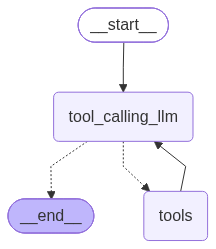

In [60]:
# StateGraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def tool_calling_llm(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message(result) from assisstant is a tool call -> tool condition routes to tools
    #If latest message(result) from assisstant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [61]:
response=graph.invoke({"messages": "Give me the recent ai news and then multiply 5 by 10"})
for m in response["messages"]:
    print(m.pretty_print())

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
None
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3dcc79cd-5733-4593-9dc9-76a9c9e94ddd)
 Call ID: fc_3dcc79cd-5733-4593-9dc9-76a9c9e94ddd
  Args:
    query: AI news October 2026
    search_depth: advanced
    time_range: month
None
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.facebook.com/NikeeluGundaofficial/posts/5-big-ai-updates-you-should-know-today-october-7-2026ai-is-moving-beyond-chatbot/1773372201461569", "title": "Nikeelu Gunda", "content": "Log in\n\nLog in\n\nForgotten account?\n\n## Nikeelu Gunda's post\n\n  \n\n[](\n\n### Nikeelu Gunda\n\n4 days ago\n\n4d · Verappa · Sai Abhyankkar, Arivu, Arun

### Add Memory in Agentic Graph

In [62]:
response=graph.invoke({"messages": "Hey, My name is Nandini Amaravadi"})
for m in response["messages"]:
    print(m.pretty_print())

================================ Human Message =================================

Hey, My name is Nandini Amaravadi
None
================================== Ai Message ==================================

Hello Nandini! Nice to meet you. How can I assist you today?
None


In [63]:
response=graph.invoke({"messages": "Hey, What is my Name?"})
for m in response["messages"]:
    print(m.pretty_print())

================================ Human Message =================================

Hey, What is my Name?
None
================================== Ai Message ==================================

I’m afraid I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!
None


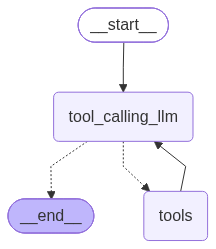

In [66]:
# StateGraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory=MemorySaver()

def tool_calling_llm(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message(result) from assisstant is a tool call -> tool condition routes to tools
    #If latest message(result) from assisstant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [67]:
config={"configurable": {"thread_id": 1}}

response=graph.invoke({"messages": "Hi my name is Nandini Amaravadi"}, config=config)
response

{'messages': [HumanMessage(content='Hi my name is Nandini Amaravadi', additional_kwargs={}, response_metadata={}, id='609c79b8-9628-4c4e-a054-513323d1809e'),
  AIMessage(content='Hello Nandini! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi my name is Nandini Amaravadi". Probably they want a greeting. Should respond politely, ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 352, 'total_tokens': 412, 'completion_time': 0.123443224, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.01620308, 'prompt_tokens_details': None, 'queue_time': 0.390375488, 'total_time': 0.139646304}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e1a78f200e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a130b3-daec-7052-9732-b5104db58ee3-0', tool_calls=[], invalid_tool_calls=[], usage_metadata=

In [68]:
response["messages"][-1].content

'Hello Nandini! 👋 Nice to meet you. How can I assist you today?'

In [70]:
response=graph.invoke({"messages": "Hey, do you know my name?"}, config=config)
response["messages"][-1].content

'Yes—I remember you introduced yourself as **Nandini\u202fAmaravadi**. How can I help you today?'

### Streaming

Methods: stream() and astream()

These methods are sync and async methods for streaming back results

Additional parameters in streaming modes for graph state

values-> This streams the full state of the graph after each node is called

updates-> This streams updates to the state of the graph after each node is called

In [71]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()



In [72]:
def superbot(state: State):
    return {"messages": [llm.invoke(state["messages"])] }

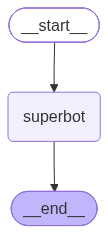

In [74]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

graph_builder=StateGraph(State)
graph_builder.add_node("superbot",superbot)

graph_builder.add_edge(START,"superbot")
graph_builder.add_edge("superbot",END)

graph=graph_builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [76]:
config={"configurable": {"thread_id":1}}

for chunk in graph.stream({"messages": "Hi my name is Nandini Amaravadi"}, config=config, stream_mode="updates"):
    print(chunk)


{'superbot': {'messages': [AIMessage(content='Hello Nandini! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Nandini Amaravadi". Probably they want a greeting. We should respond politely, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 68, 'prompt_tokens': 81, 'total_tokens': 149, 'completion_time': 0.144071039, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.035535787, 'prompt_tokens_details': None, 'queue_time': 0.343900867, 'total_time': 0.179606826}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a130cb-2fe1-7f10-886c-76e68a26f3e6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 81, 'output_tokens': 68, 'total_tokens': 149, 'output_token_details': 

In [77]:
config={"configurable": {"thread_id":1}}

for chunk in graph.stream({"messages": "Hey, I like to play football"}, config=config, stream_mode="values"):
    print(chunk)


{'messages': [HumanMessage(content='Hi my name is Nandini Amaravadi', additional_kwargs={}, response_metadata={}, id='d2fbca2b-2d8b-41f7-a73d-83caa2eb772f'), AIMessage(content='Hello Nandini! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Nandini Amaravadi". Probably they want a greeting. We should respond politely, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 68, 'prompt_tokens': 81, 'total_tokens': 149, 'completion_time': 0.144071039, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.035535787, 'prompt_tokens_details': None, 'queue_time': 0.343900867, 'total_time': 0.179606826}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a130cb-2fe1-7f10-886c-76e68a26f3e6-0', tool_call

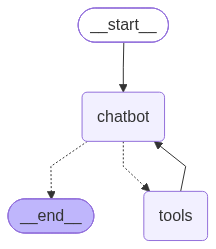

In [80]:
from typing import Annotated
from langgraph.graph import StateGraph, START, END
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

from langgraph.types import Command, Interrupt, interrupt

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder=StateGraph(State)

@tool
def human_assistant(query:str)->str:
    """Request assistance from a human"""
    human_response=interrupt({"query" : query})
    return human_response["data"]

tool=TavilySearch(max_length=2)
tools=[tool,human_assistant]
llm_with_tools=llm.bind_tools(tools)

def chatbot(state:State):
    message= {"messages":[llm_with_tools.invoke(state["messages"])]}
    #we will be interrupting during tool execution
    # we disabled parallel tool_calling to avoid repeating any
    #tool invocation when resume
    return message

graph_builder.add_node("chatbot",chatbot)

tool_node=ToolNode(tools=tools)
graph_builder.add_node("tools",tool_node)
graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)
graph_builder.add_edge("tools","chatbot")
graph_builder.add_edge(START,"chatbot")

graph=graph_builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))





In [81]:
user_input="I need some expert guidance and assistance for building AI Agent. Could you request assistance for me?"
config={"configurable": {"thread_id":1}}

events=graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values",
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building AI Agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistant (fc_72a8dddb-325f-476b-9633-64d848b064c9)
 Call ID: fc_72a8dddb-325f-476b-9633-64d848b064c9
  Args:
    query: User Nandini Amaravadi is requesting expert guidance and assistance for building an AI Agent. Please provide detailed help.
================================== Ai Message ==================================
Tool Calls:
  human_assistant (fc_72a8dddb-325f-476b-9633-64d848b064c9)
 Call ID: fc_72a8dddb-325f-476b-9633-64d848b064c9
  Args:
    query: User Nandini Amaravadi is requesting expert guidance and assistance for building an AI Agent. Please provide detailed help.


In [83]:
human_response=(
    "We, the experts are here to help We'd recommend you to check out LangGraph to build your agent."
    "It's much more reliable and extensible than autonomous agents."
)

humman_command=Command(resume={"data": human_response})
events=graph.stream(
    humman_command,
    config,
    stream_mode="values",
)
for event in events:
    if "messages" in event:
         event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistant (fc_72a8dddb-325f-476b-9633-64d848b064c9)
 Call ID: fc_72a8dddb-325f-476b-9633-64d848b064c9
  Args:
    query: User Nandini Amaravadi is requesting expert guidance and assistance for building an AI Agent. Please provide detailed help.
================================= Tool Message =================================
Name: human_assistant

We, the experts are here to help We'd recommend you to check out LangGraph to build your agent.It's much more reliable and extensible than autonomous agents.
================================== Ai Message ==================================

Great—our AI‑agent experts have been notified and will be with you shortly! In the meantime, it can be helpful to think about a few details so they can dive right in:

1. **Purpose & Scope**  
   * What specific tasks do you want the agent to handle (e.g., data extraction, customer support, code generation, r